In [99]:
import pandas as pd
import numpy as np

In [100]:
data = pd.read_parquet("divar_clean.parquet")

In [101]:
data["city_slug"] = data["city_slug"].astype("string").str.lower()

In [102]:
data.shape

(1000000, 127)

In [103]:
city_classif = pd.read_csv("iran_city_classification.csv")

In [104]:
city_classif.columns = ["name", "city_class"]

In [105]:
city_classif["name"] = city_classif["name"].astype("string").str.lower()

In [106]:
city_classif.dtypes

name          string
city_class       str
dtype: object

In [107]:
columns = city_classif.columns.tolist()
print(columns[0])
print(columns[1])
print(columns) 

name
city_class
['name', 'city_class']


In [108]:
city_classif["name"]

0                karaj
1               tehran
2              mashhad
3                ahvaz
4           kermanshah
            ...       
235              baneh
236    ahmadsar-gourab
237             saqqez
238             mianeh
239         lavandevil
Name: name, Length: 240, dtype: string

In [109]:
print("city_class", city_classif["city_class"].unique())

city_class <ArrowStringArray>
['کلان‌شهر', 'شهر کوچک']
Length: 2, dtype: str


In [110]:
city_classif["city_class"] = city_classif["city_class"].replace({
    "کلان‌شهر": "metro",
    'شهر کوچک': "small_city"
})

In [111]:
print(city_classif["city_class"].unique())

<ArrowStringArray>
['metro', 'small_city']
Length: 2, dtype: str


In [112]:
city_map = city_classif.set_index("name")["city_class"].to_dict()
print(f"cities in reference: {len(city_map)}")

cities in reference: 240


In [113]:
data["city_class"] = data["city_slug"].astype("string").map(city_map)
data["city_class_imputed"] = data["city_class"].isna()
data["city_class"] = data["city_class"].fillna("small_city").astype("category")

In [114]:
print(data["city_class"].value_counts())
data["city_class"].value_counts().sum()

city_class
small_city    535201
metro         464799
Name: count, dtype: int64


np.int64(1000000)

In [115]:
unmapped_cities = (
    data.loc[data["city_class_imputed"], "city_slug"]
    .value_counts()
    .head(20)
)
print(unmapped_cities)

city_slug
langarud                1461
andimeshk               1361
qorveh                   867
garmsar                  839
bandar-imam-khomeini     786
takestan                 783
fasa-city                774
aligudarz                744
khoshkbijar              733
siahkal                  711
bukan                    667
dehdasht                 663
nurabad                  657
fereydunkenar            616
norabad                  602
shaft                    580
koohsar                  548
lordegan                 498
aliabad-katul            489
kamyaran                 487
Name: count, dtype: int64[pyarrow]


In [116]:
# checking for the houses and not office or shops

residential_cats = [
    "apartment-sell", "apartment-rent",
    "house-villa-sell", "house-villa-rent",
    "villa", "suite-apartment",
]

residential = data[data["cat3_slug"].astype("string").isin(residential_cats)].copy()

print(len(residential))

731060


In [117]:
residential["building_size"] = pd.to_numeric(residential["building_size"], errors="coerce")

In [118]:
residential["building_size"]

0         500.0
1          60.0
2         132.0
4         115.0
5         100.0
          ...  
999995    180.0
999996    110.0
999997    200.0
999998     70.0
999999     40.0
Name: building_size, Length: 731060, dtype: float64

In [119]:
def clean_building_size(df, col='building_size', min_limit=20, max_limit=2500):
    hard_mask = df[col].notna() & ~df[col].between(min_limit, max_limit)
    df.loc[hard_mask, col] = pd.NA

    positive = df[col].where(df[col] > 0)
    log_vals = np.log10(positive)

    q1 = log_vals.quantile(0.25)
    q3 = log_vals.quantile(0.75)
    iqr = q3 - q1
    
    low = 10 ** (q1 - 2.0 * iqr)
    high = 10 ** (q3 + 2.0 * iqr)
    
    soft_mask = df[col].notna() & ~df[col].between(low, high)
    df.loc[soft_mask, col] = pd.NA
    return df

In [120]:
data = clean_building_size(data, col='building_size', min_limit=20, max_limit=2500)
residential = clean_building_size(residential, col='building_size', min_limit=20, max_limit=2500)

In [121]:
metro_area = residential.loc[residential["city_class"] == "metro", "building_size"].dropna()
small_area = residential.loc[residential["city_class"] == "small_city", "building_size"].dropna()

In [122]:
print(f"metro:      n = {len(metro_area):>7}, mean = {metro_area.mean():>7.1f}, median = {metro_area.median():>7.1f}")
print(f"small_city: n = {len(small_area):>7}, mean = {small_area.mean():>7.1f}, median = {small_area.median():>7.1f}")

metro:      n =  358499, mean =   110.5, median =   100.0
small_city: n =  350614, mean =   112.7, median =   100.0


In [123]:
from scipy.stats import shapiro

rng = np.random.default_rng(42)

metro_sample = rng.choice(
    metro_area, size=min(5000, len(metro_area)), replace=False
)
small_sample = rng.choice(
    small_area, size=min(5000, len(small_area)), replace=False
)

shapiro_metro = shapiro(metro_sample)
shapiro_small = shapiro(small_sample)

print("Shapiro-Wilk on random 5000 per group:")
print(f"metro:      W={shapiro_metro.statistic:.4f}, p={shapiro_metro.pvalue:.2e}")
print(f"small_city: W={shapiro_small.statistic:.4f}, p={shapiro_small.pvalue:.2e}")

Shapiro-Wilk on random 5000 per group:
metro:      W=0.8512, p=3.90e-56
small_city: W=0.8232, p=2.79e-59


<div dir="rtl" align="right">
<p>اگر p-value آزمون Shapiro-Wilk کمتر از ۰.۰۵ باشد، فرض نرمال بودن رد می‌شود. با این حال، چون حجم نمونه بسیار بزرگ است (n > 300,000)، قضیه‌ی حد مرکزی باعث می‌شود آزمون t همچنان معتبر باشد. علاوه بر این، آزمون Mann-Whitney به عنوان آزمون غیرپارامتری نتیجه را تأیید می‌کند.</p>
</div>

<div dir="rtl" align="right">

<h3>فرضیه‌ی صفر و جایگزین</h3>

<ul>
<li><strong>H₀:</strong> میانگین مساحت کلان‌شهرها حداقل برابر شهرهای کوچک است (<code>μ_metro ≥ μ_small_city</code>).</li>
<li><strong>H₁:</strong> میانگین مساحت کلان‌شهرها کمتر است (<code>μ_metro &lt; μ_small_city</code>).</li>
</ul>

<p>اگر <code>p &lt; 0.05</code> باشد، H₀ رد و H₁ پذیرفته می‌شود. آزمون یک‌طرفه است چون صورت مسئله جهت مشخصی داده («کمتر است»).</p>

</div>

<div dir="rtl" align="right">

<h3>اجرای آزمون‌های آماری</h3>
<p>دو آزمون یک‌طرفه اجرا می‌کنیم:</p>
<ul>
<li><strong>Welch t-test</strong> — مقایسه‌ی میانگین دو گروه. فرض برابری واریانس را کنار می‌گذارد.</li>
<li><strong>Mann-Whitney U</strong> — مقایسه‌ی رتبه‌ها. مقاوم به مقادیر پرت.</li>
</ul>
<p>هر دو آزمون جهت فرضیه را در نظر می‌گیرند (کلان‌شهر کوچک‌تر است).</p>

</div>

In [124]:
from scipy.stats import ttest_ind, mannwhitneyu

t_stat, p_one_t = ttest_ind(metro_area, small_area, equal_var=False, alternative="less")
u_stat, p_one_mw = mannwhitneyu(metro_area, small_area, alternative="less")

print(f"Welch t-test  :  t = {t_stat:+.3f},  one-sided p = {p_one_t:.2e}")
print(f"Mann-Whitney  :  U = {u_stat:.0f},  one-sided p = {p_one_mw:.2e}")

Welch t-test  :  t = -16.591,  one-sided p = 4.17e-62
Mann-Whitney  :  U = 61300895914,  one-sided p = 2.36e-72


In [125]:
def cohen_d(x, y):
    nx, ny = len(x), len(y)
    vx, vy = x.var(ddof=1), y.var(ddof=1)
    pooled_sd = np.sqrt(((nx - 1) * vx + (ny - 1) * vy) / (nx + ny - 2))
    return (x.mean() - y.mean()) / pooled_sd

d = cohen_d(metro_area, small_area)
print(f"Cohen's d = {d:.3f}")

Cohen's d = -0.039


<div dir="rtl" align="right">
<p>مقدار Cohen's d برابر با ‎-0.039 است. طبق قاعده‌ی سرانگشتی، ‎|d| < 0.2 به معنای اثر ناچیز است. بنابراین اگرچه اختلاف آماری بسیار معنادار است، اختلاف عملی کوچک است. این نتیجه با یکسان بودن میانه‌ها (۱۰۰ در مقابل ۱۰۰ متر مربع) سازگار است.</p>
</div>

<div dir="rtl" align="right">

<h3>آزمون مقاومت — حذف شهرهای پیش‌فرض</h3>
<p>یک نسخه‌ی سخت‌گیرانه می‌سازیم که فقط سطرهایی را نگه می‌دارد که شهرشان در فایل مرجع واقعاً وجود دارد.</p>
<p>اگر نتیجه در هر دو حالت یکسان باشد، فرضیه به‌طور قابل‌اعتماد تأیید یا رد می‌شود.</p>

</div>

In [126]:
strict = residential[~residential["city_class_imputed"]]

In [127]:
metro_strict = strict.loc[strict["city_class"] == "metro", "building_size"].dropna()
small_strict = strict.loc[strict["city_class"] == "small_city", "building_size"].dropna()

<div dir="rtl" align="right">

<h3>مقایسه‌ی دو نسخه — all و strict</h3>
<p>آزمون را روی هر دو نسخه اجرا می‌کنیم و نتایج را کنار هم می‌گذاریم تا ببینیم نتیجه به حضور شهرهای پیش‌فرض حساس است یا نه.</p>

</div>

In [ ]:
for name, m, s in [("all", metro_area, small_area), ("strict", metro_strict, small_strict)]:
    t, p1 = ttest_ind(m, s, equal_var=False, alternative="less")
    u, pmw = mannwhitneyu(m, s, alternative="less")
    print(f"{name:>6}:  n_metro={len(m):>6},  n_small={len(s):>6},  "
          f"t={t:+.2f},  p_t={p1:.2e},  p_mw={pmw:.2e}")

   all:  n_metro=358499,  n_small=350614,  t=-16.59,  p_t=4.17e-62,  p_mw=2.36e-72
strict:  n_metro=358499,  n_small=332162,  t=-14.66,  p_t=6.03e-49,  p_mw=1.16e-55


<div dir="rtl" align="right">

<h3>رسم نمودارها</h3>
<ul>
<li>نمودار جعبه‌ای: توزیع مساحت در دو گروه</li>
<li>نمودار میله‌ای: میانگین مساحت در دو گروه</li>
</ul>
<p>مقادیر پرت در جعبه‌ها نمایش داده نمی‌شوند تا خواندن نمودار راحت‌تر باشد.</p>

</div>

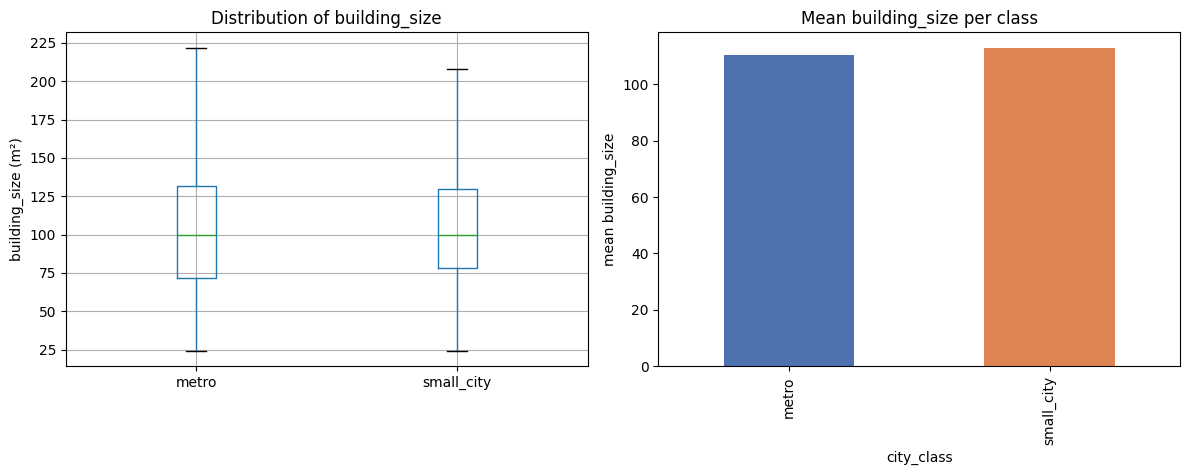

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

residential.boxplot(
    column="building_size", by="city_class",
    ax=axes[0], showfliers=False,
)
axes[0].set_title("Distribution of building_size")
axes[0].set_xlabel("")
axes[0].set_ylabel("building_size (m²)")

means = residential.groupby("city_class", observed=True)["building_size"].mean()
means.plot(kind="bar", ax=axes[1], color=["#4c72b0", "#dd8452"])
axes[1].set_title("Mean building_size per class")
axes[1].set_ylabel("mean building_size")

plt.suptitle("")
plt.tight_layout()
plt.show()

<div dir="rtl" align="right">

<h3>نتیجه‌گیری نهایی</h3>
<p>سه شرط بررسی می‌شود:</p>
<ol>
<li>جهت اختلاف درست است (<code>t_stat &lt; 0</code>)</li>
<li>t-test معنادار است (<code>p &lt; 0.05</code>)</li>
<li>Mann-Whitney معنادار است (<code>p &lt; 0.05</code>)</li>
</ol>
<p>اگر هر سه برقرار باشند، فرضیه تأیید می‌شود.</p>

</div>

In [ ]:
supported = (t_stat < 0) and (p_one_t < 0.05) and (p_one_mw < 0.05)

if supported:
    print("Hypothesis SUPPORTED: metro houses are significantly smaller.")
    print(f"  metro mean      = {metro_area.mean():.1f} m²  (n = {len(metro_area)})")
    print(f"  small city mean = {small_area.mean():.1f} m²  (n = {len(small_area)})")
    print(f"  Welch t-test p  = {p_one_t:.2e}")
    print(f"  Mann-Whitney p  = {p_one_mw:.2e}")
    print(f"  Cohen's d       = {d:.3f}")
else:
    print("Hypothesis NOT supported by the data.")
    print(f"  t-test p = {p_one_t:.2e},  MW p = {p_one_mw:.2e}")

Hypothesis SUPPORTED: metro houses are significantly smaller.
  metro mean      = 110.5 m²  (n = 358499)
  small city mean = 112.7 m²  (n = 350614)
  Welch t-test p  = 4.17e-62
  Mann-Whitney p  = 2.36e-72
  Cohen's d       = -0.039


<div dir="rtl" align="right">

<p><strong>نتیجه:</strong> فرضیه تأیید شد. میانگین مساحت خانه‌های کلان‌شهری ۱۱۰.۵ متر مربع و در شهرهای کوچک ۱۱۲.۷ متر مربع است. هر دو آزمون معناداری بسیار بالایی نشان می‌دهند (p &lt; 10⁻⁶⁰).</p>

<p><strong>اندازه‌ی اثر:</strong> Cohen's d ≈ -0.039 است که در دسته‌ی اثر ناچیز قرار می‌گیرد. یعنی اختلاف آماری قوی است، اما اختلاف عملی کوچک است. میانه‌ها نیز یکسان‌اند (۱۰۰ در مقابل ۱۰۰ متر مربع).</p>

<p><strong>محدودیت‌ها:</strong></p>
<ul>
<li>داده‌ی مرجع فقط دو دسته‌ی <code>metro</code> و <code>small_city</code> دارد؛ بنابراین این آزمون «کلان‌شهر در مقابل شهر کوچک» را بررسی می‌کند، نه روستاها.</li>
<li>شهرهایی که در فایل مرجع نبودند، به‌طور پیش‌فرض <code>small_city</code> در نظر گرفته شدند. نسخه‌ی <code>strict</code> بدون این شهرها نیز اجرا شد و نتیجه تغییر نکرد.</li>
<li>آزمون Shapiro-Wilk روی نمونه‌ی تصادفی نشان داد داده‌ها نرمال نیستند. با این حال، با حجم نمونه‌ی بزرگ (n > 350,000)، قضیه‌ی حد مرکزی آزمون t را معتبر می‌کند و Mann-Whitney نیز نتیجه را تأیید می‌کند.</li>
</ul>

</div>